   Hours  Scores
0    7.6    75.0
1    4.7    51.0
2    8.3    85.0
3    6.9    72.0
4    1.8    22.0
Shape: (25, 2)
Correlation:
            Hours    Scores
Hours   1.000000  0.992274
Scores  0.992274  1.000000


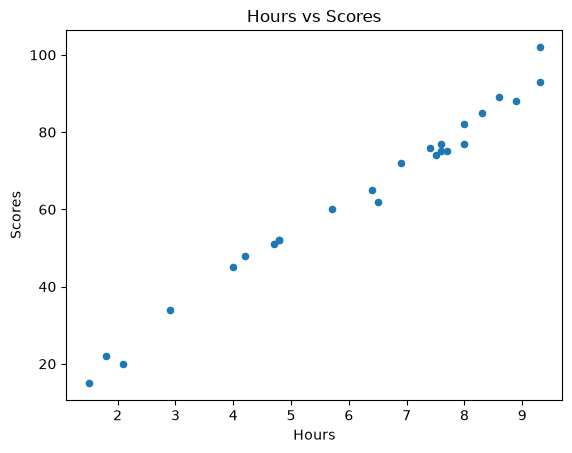


Slope (a): 9.639120343948555
Intercept (b): 4.344148308792789
9.5 hours ka predicted score: 95.91579157630406

Actual vs Predicted:
   Actual  Predicted
0    20.0      24.59
1    60.0      59.29
2    75.0      77.60
3    89.0      87.24
4    88.0      90.13

MAE : 2.36
MSE : 7.19
RMSE: 2.68
R2  : 0.99


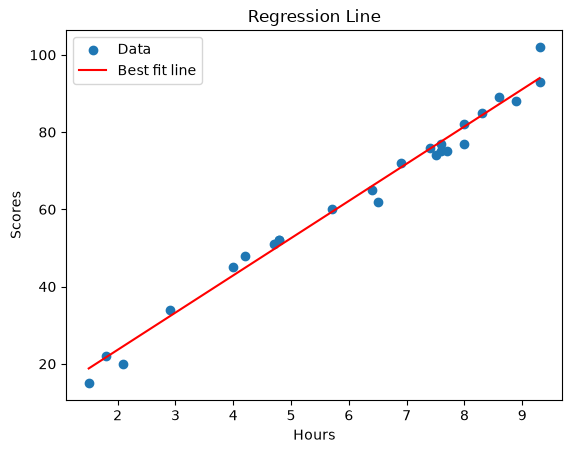


Intercept: 352.9911376171166
                    Coefficient
Average_income        -0.051611
Paved_Highways        -0.004062
Driver_licence_pct  1369.975675
Petrol_tax           -36.507740

MAE : 40.42
RMSE: 48.77
Train R2: 0.87
Test  R2: 0.85


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
rng = np.random.default_rng(SEED)

# ============================================
# PART 1: SIMPLE LINEAR REGRESSION (Hours -> Score)
# ============================================

# Fake data banate hain (asli relation: score ~ 9.7*hours + 2.8)
hours = rng.uniform(1, 9.5, 25)
scores = 9.7 * hours + 2.8 + rng.normal(0, 4, 25)
df = pd.DataFrame({"Hours": hours.round(1), "Scores": scores.round(0)})

print(df.head())
print("Shape:", df.shape)
print("Correlation:\n", df.corr())

# Scatter plot
df.plot.scatter(x="Hours", y="Scores", title="Hours vs Scores")
plt.show()

# X ko 2D hona chahiye, isliye double brackets
X = df[["Hours"]]
y = df["Scores"]

# Train/Test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)

# Model train
model = LinearRegression()
model.fit(X_train, y_train)

print("\nSlope (a):", model.coef_[0])
print("Intercept (b):", model.intercept_)

# Naya prediction: 9.5 ghante parho to score?
print("9.5 hours ka predicted score:", model.predict(pd.DataFrame({"Hours": [9.5]}))[0])

# Test data par prediction aur evaluation
y_pred = model.predict(X_test)
print("\nActual vs Predicted:")
print(pd.DataFrame({"Actual": y_test.values, "Predicted": y_pred.round(2)}))

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
print(f"\nMAE : {mae:.2f}")
print(f"MSE : {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R2  : {r2_score(y_test, y_pred):.2f}")

# Line ke saath plot
plt.scatter(X, y, label="Data")
plt.plot(X.sort_values("Hours"), model.predict(X.sort_values("Hours")),
         color="red", label="Best fit line")
plt.xlabel("Hours")
plt.ylabel("Scores")
plt.legend()
plt.title("Regression Line")
plt.show()

# ============================================
# PART 2: MULTIPLE LINEAR REGRESSION (4 features)
# ============================================

n = 48
data = pd.DataFrame({
    "Average_income": rng.normal(4200, 570, n),
    "Paved_Highways": rng.uniform(400, 17000, n),
    "Driver_licence_pct": rng.uniform(0.45, 0.72, n),
    "Petrol_tax": rng.uniform(5, 10, n),
})
data["Consumption"] = (
    361
    - 0.05 * data["Average_income"]
    - 0.004 * data["Paved_Highways"]
    + 1347 * data["Driver_licence_pct"]
    - 37 * data["Petrol_tax"]
    + rng.normal(0, 50, n)
)

X = data.drop(columns="Consumption")
y = data["Consumption"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)

multi = LinearRegression()
multi.fit(X_train, y_train)

# Coefficients ko table mein dekhein
print("\nIntercept:", multi.intercept_)
print(pd.DataFrame(multi.coef_, index=X.columns, columns=["Coefficient"]))

y_pred = multi.predict(X_test)
print(f"\nMAE : {mean_absolute_error(y_test, y_pred):.2f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.2f}")

# Overfitting check: train score vs test score
print(f"Train R2: {multi.score(X_train, y_train):.2f}")
print(f"Test  R2: {multi.score(X_test, y_test):.2f}")
